<a href="https://colab.research.google.com/github/amadawi79-commits/thakaa-flow-training/blob/main/week3/day17/day17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 17 — Telco Customer Churn
[لوحة تحليل ترك الخدمة](https://telco-churn-dashboard-pqskvrcxhpbr6dbdlbtwtr.streamlit.app/)

## المهمة 1 — فهم المشكلة

أحلل بيانات عملاء شركة اتصالات لمعرفة الفئات التي يرتفع فيها معدل ترك الخدمة، وما الخصائص المرتبطة بذلك.

العمود المستهدف هو `Churn`. القيمة `Yes` تعني أن العميل ترك الشركة، والقيمة `No` تعني أنه استمر.

يستفيد فريق الاحتفاظ بالعملاء من التحليل في تحديد الفئات التي يمكن استهدافها بعروض مناسبة أو التواصل معها مبكرًا.

In [2]:

import io

import pandas as pd
from google.colab import files

uploaded = files.upload()
filename, contents = next(iter(uploaded.items()))
df = pd.read_csv(io.BytesIO(contents))

print(f"عدد الصفوف: {df.shape[0]:,}")
print(f"عدد الأعمدة: {df.shape[1]}")
display(df.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
عدد الصفوف: 7,043
عدد الأعمدة: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. أول نظرة على البيانات

أفحص أنواع الأعمدة والقيم الناقصة والصفوف المكررة، وأراجع إحصاءات الأعمدة الرقمية قبل التنظيف.

In [3]:
blank_counts = df.select_dtypes(include=["object", "string"]).apply(
    lambda column: column.str.strip().eq("").sum()
)

overview = pd.DataFrame({
    "نوع العمود": df.dtypes.astype(str),
    "القيم الناقصة": df.isna().sum(),
    "الخانات الفارغة أو المسافات": blank_counts.reindex(df.columns, fill_value=0)
})

display(overview)

print("عدد الصفوف المكررة بالكامل:", df.duplicated().sum())
print("عدد معرّفات العملاء المكررة:", df["customerID"].duplicated().sum())

display(df.describe().round(2))

,نوع العمود,القيم الناقصة,الخانات الفارغة أو المسافات
customerID,object,0,0
gender,object,0,0
SeniorCitizen,int64,0,0
Partner,object,0,0
Dependents,object,0,0
tenure,int64,0,0
PhoneService,object,0,0
MultipleLines,object,0,0
InternetService,object,0,0
OnlineSecurity,object,0,0


عدد الصفوف المكررة بالكامل: 0
عدد معرّفات العملاء المكررة: 0


,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


## 3. التحليل الاستكشافي (EDA)

أقارن عدد العملاء الذين تركوا الخدمة بمن استمروا، ثم أحسب نسبة ترك الخدمة داخل كل نوع عقد.

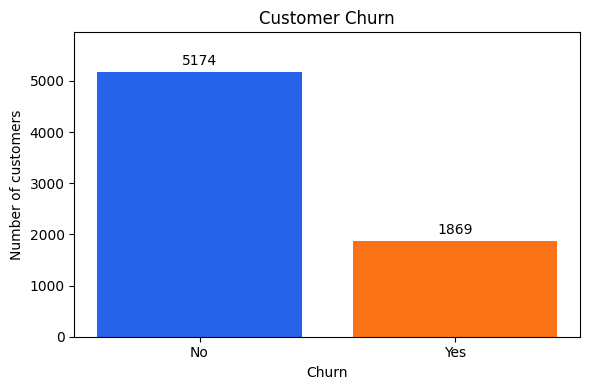

ترك الخدمة 1,869 عميلًا من أصل 7,043 (26.5%).


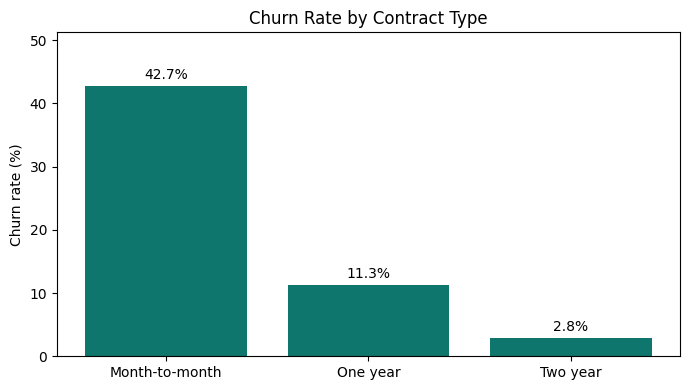

أعلى نسبة ترك للخدمة كانت في عقد Month-to-month بنسبة 42.7%.


In [4]:
import matplotlib.pyplot as plt

# الرسم الأول: عدد العملاء حسب حالة ترك الخدمة
churn_counts = df["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
churn_rate = churn_counts["Yes"] / len(df) * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(churn_counts.index, churn_counts.values, color=["#2563eb", "#f97316"])
ax.bar_label(bars, padding=3)
ax.set(title="Customer Churn", xlabel="Churn", ylabel="Number of customers")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

print(f"ترك الخدمة {churn_counts['Yes']:,} عميلًا من أصل {len(df):,} ({churn_rate:.1f}%).")

# الرسم الثاني: نسبة ترك الخدمة داخل كل نوع عقد
contract_rates = (
    df["Churn"].eq("Yes").groupby(df["Contract"]).mean().mul(100)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(contract_rates.index, contract_rates.values, color="#0f766e")
ax.bar_label(bars, labels=[f"{rate:.1f}%" for rate in contract_rates], padding=3)
ax.set(title="Churn Rate by Contract Type", ylabel="Churn rate (%)")
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

print(
    f"أعلى نسبة ترك للخدمة كانت في عقد {contract_rates.idxmax()} "
    f"بنسبة {contract_rates.max():.1f}%."
)

### مدة الاشتراك والرسوم الشهرية

أقارن توزيع مدة الاشتراك والرسوم الشهرية بين العملاء الذين تركوا الخدمة والعملاء الذين استمروا، وأستخدم الوسيط لتلخيص الفرق بين المجموعتين.

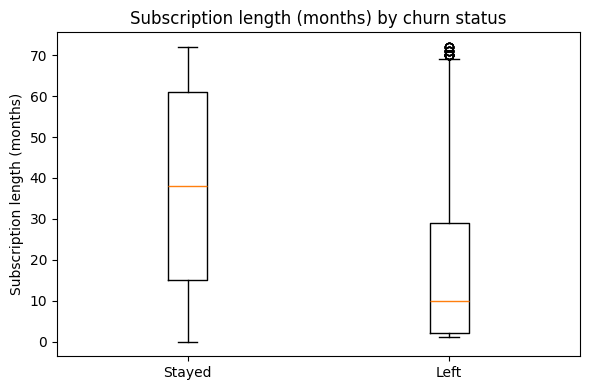

وسيط Subscription length (months) لمن استمروا 38.00 شهر، ولمن تركوا الخدمة 10.00 شهر.


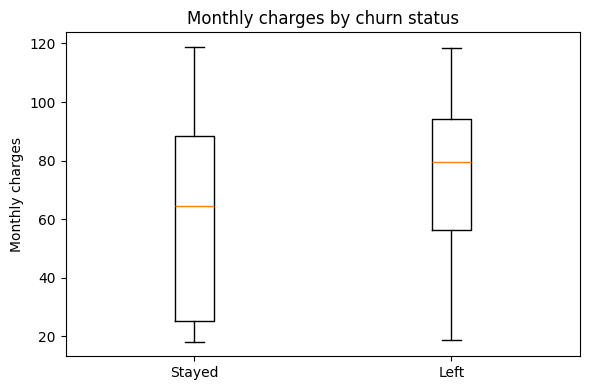

وسيط Monthly charges لمن استمروا 64.43 وحدة نقدية، ولمن تركوا الخدمة 79.65 وحدة نقدية.


In [5]:
groups = ["No", "Yes"]
columns = [
    ("tenure", "Subscription length (months)", "شهر"),
    ("MonthlyCharges", "Monthly charges", "وحدة نقدية"),
]

for column, label, unit in columns:
    values = [df.loc[df["Churn"].eq(group), column].dropna() for group in groups]

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.boxplot(values, showmeans=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Stayed", "Left"])
    ax.set(title=f"{label} by churn status", ylabel=label)
    plt.tight_layout()
    plt.show()

    print(
        f"وسيط {label} لمن استمروا {values[0].median():.2f} {unit}، "
        f"ولمن تركوا الخدمة {values[1].median():.2f} {unit}."
    )

## 4. تنظيف البيانات وسجل القرارات

أزيل المسافات الزائدة من النصوص وأحوّل إجمالي الرسوم إلى رقم. إذا كانت خانة إجمالي الرسوم فارغة ومدة الاشتراك صفر شهر، أسجّل الإجمالي بصفر وأوثّق عدد الصفوف التي تأثرت.

In [6]:
clean = df.copy()
text_columns = clean.select_dtypes(include=["object", "string"]).columns

stripped = clean[text_columns].apply(lambda column: column.str.strip())
changed_text = (
    clean[text_columns].notna() & clean[text_columns].ne(stripped)
).any(axis=1)
clean[text_columns] = stripped

total = clean["TotalCharges"]
blank_total = total.isna() | total.eq("")
new_customers = blank_total & clean["tenure"].eq(0)

clean["TotalCharges"] = pd.to_numeric(total, errors="coerce")
clean.loc[new_customers, "TotalCharges"] = 0

decision_log = pd.DataFrame([
    ["إزالة المسافات الزائدة", "توحيد النصوص وكشف الخانات الفارغة", changed_text.sum()],
    ["تحويل القيم المقروءة في TotalCharges إلى أرقام", "إجمالي الرسوم قيمة رقمية", clean["TotalCharges"].notna().sum() - new_customers.sum()],
    ["تسجيل إجمالي الرسوم الفارغ بصفر", "مدة الاشتراك صفر شهر في هذه الصفوف", new_customers.sum()],
], columns=["القرار", "السبب", "عدد الصفوف المتأثرة"])

display(decision_log)
print("القيم الناقصة المتبقية في TotalCharges:", clean["TotalCharges"].isna().sum())
print("قيم Churn بعد التنظيف:", clean["Churn"].unique().tolist())
print(f"عدد الصفوف بعد التنظيف: {len(clean):,}")

,القرار,السبب,عدد الصفوف المتأثرة
0,إزالة المسافات الزائدة,توحيد النصوص وكشف الخانات الفارغة,11
1,تحويل القيم المقروءة في TotalCharges إلى أرقام,إجمالي الرسوم قيمة رقمية,7032
2,تسجيل إجمالي الرسوم الفارغ بصفر,مدة الاشتراك صفر شهر في هذه الصفوف,11


القيم الناقصة المتبقية في TotalCharges: 0
قيم Churn بعد التنظيف: ['No', 'Yes']
عدد الصفوف بعد التنظيف: 7,043


## 5. هندسة الخصائص (Feature Engineering)

أنشأت عمود `TenureGroup` لتقسيم مدة الاشتراك إلى أربع فئات. يساعدني هذا التقسيم على مقارنة نسبة ترك الخدمة بين المشتركين الجدد والعملاء الذين أمضوا مدة أطول مع الشركة.

,Customers,Left,ChurnRate
TenureGroup,,,
0–6,1481,784,52.9
7–12,705,253,35.9
13–24,1024,294,28.7
25+,3833,538,14.0


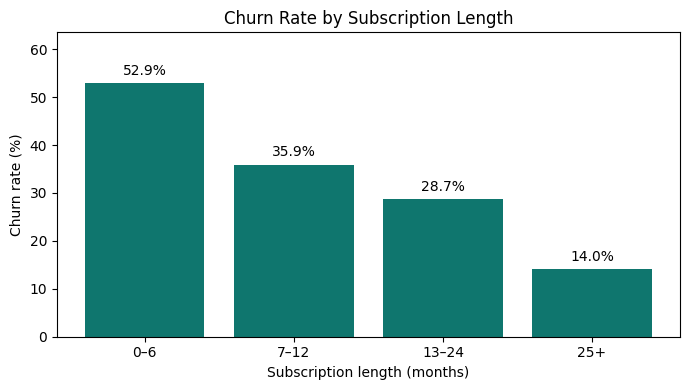

أعلى نسبة ترك للخدمة كانت في فئة 0–6 شهرًا، وبلغت 52.9%.
تم حفظ telco_clean.csv داخل كولاب.


In [7]:
clean["TenureGroup"] = pd.cut(
    clean["tenure"],
    bins=[-1, 6, 12, 24, float("inf")],
    labels=["0–6", "7–12", "13–24", "25+"]
)

tenure_summary = (
    clean.assign(LeftService=clean["Churn"].eq("Yes"))
    .groupby("TenureGroup", observed=True)["LeftService"]
    .agg(Customers="size", Left="sum", ChurnRate="mean")
)

tenure_summary["ChurnRate"] *= 100
display(tenure_summary.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
rates = tenure_summary["ChurnRate"]
bars = ax.bar(rates.index.astype(str), rates, color="#0f766e")
ax.bar_label(bars, labels=[f"{rate:.1f}%" for rate in rates], padding=4)
ax.set(
    title="Churn Rate by Subscription Length",
    xlabel="Subscription length (months)",
    ylabel="Churn rate (%)"
)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

print(f"أعلى نسبة ترك للخدمة كانت في فئة {rates.idxmax()} شهرًا، وبلغت {rates.max():.1f}%.")

clean.to_csv("telco_clean.csv", index=False)
print("تم حفظ telco_clean.csv داخل كولاب.")

## 6. اختيار الخصائص (Feature Selection)

اخترت مدة الاشتراك والرسوم الشهرية ونوع العقد بناءً على نتائج التحليل. أستخدم مدة الاشتراك بالأشهر في ملف النموذج، وأستخدم فئاتها في الرسومات لتسهيل المقارنة. أحوّل نوع العقد إلى أعمدة رقمية، وأرمّز حالة ترك الخدمة إلى 1 للمغادر و0 للمستمر.

,العمود,القرار,الدليل أو السبب
0,tenure,اختيار,وسيط المدة 10 أشهر للمغادرين مقابل 38 للمستمرين
1,MonthlyCharges,اختيار,وسيط الرسوم 79.65 للمغادرين مقابل 64.43 للمستمرين
2,Contract,اختيار,معدل المغادرة 42.7% للعقد الشهري مقابل 2.8% لع...
3,TenureGroup,للرسومات,مشتق من مدة الاشتراك بالأشهر الموجودة في الملف
4,TotalCharges,استبعاد,إجمالي تراكمي يتأثر بمدة الاشتراك والرسوم الشهرية
5,customerID,استبعاد,"معرّف يميّز 7,043 عميلًا"


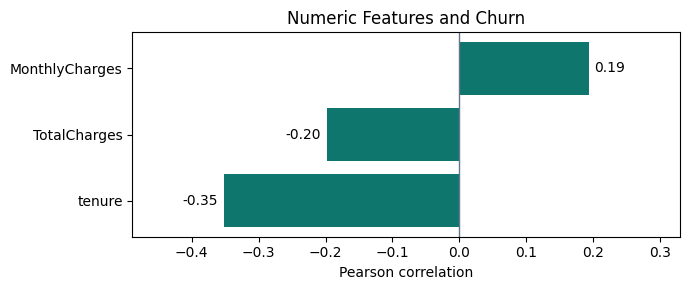

ارتباط مدة الاشتراك بترك الخدمة بلغ -0.35، ويشير إلى علاقة عكسية في هذه البيانات.
تم حفظ telco_model_ready.csv وفيه 7,043 صفًا.


,tenure,MonthlyCharges,Contract_Month-to-month,Contract_One year,Contract_Two year,Churn
0,1,29.85,1,0,0,0
1,34,56.95,0,1,0,0
2,2,53.85,1,0,0,1
3,45,42.30,0,1,0,0
4,2,70.70,1,0,0,1


In [8]:
target = clean["Churn"].map({"No": 0, "Yes": 1}).astype(int)
selected = ["tenure", "MonthlyCharges", "Contract"]

selection_log = pd.DataFrame([
    ["tenure", "اختيار", "وسيط المدة 10 أشهر للمغادرين مقابل 38 للمستمرين"],
    ["MonthlyCharges", "اختيار", "وسيط الرسوم 79.65 للمغادرين مقابل 64.43 للمستمرين"],
    ["Contract", "اختيار", "معدل المغادرة 42.7% للعقد الشهري مقابل 2.8% لعقد السنتين"],
    ["TenureGroup", "للرسومات", "مشتق من مدة الاشتراك بالأشهر الموجودة في الملف"],
    ["TotalCharges", "استبعاد", "إجمالي تراكمي يتأثر بمدة الاشتراك والرسوم الشهرية"],
    ["customerID", "استبعاد", f"معرّف يميّز {clean['customerID'].nunique():,} عميلًا"],
], columns=["العمود", "القرار", "الدليل أو السبب"])

display(selection_log)

numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
correlations = clean[numeric_columns].corrwith(target).sort_values()

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(correlations.index, correlations.values, color="#0f766e")
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.axvline(0, color="#64748b", linewidth=1)
ax.set(title="Numeric Features and Churn", xlabel="Pearson correlation")
ax.margins(x=0.25)
plt.tight_layout()
plt.show()

print(f"ارتباط مدة الاشتراك بترك الخدمة بلغ {correlations['tenure']:.2f}، ويشير إلى علاقة عكسية في هذه البيانات.")

model_ready = pd.get_dummies(clean[selected], columns=["Contract"], dtype=int)
model_ready["Churn"] = target
model_ready.to_csv("telco_model_ready.csv", index=False)

print(f"تم حفظ telco_model_ready.csv وفيه {len(model_ready):,} صفًا.")
display(model_ready.head())

## 7. النتائج والتوصيات

- ترك الخدمة 1,869 عميلًا من أصل 7,043، بنسبة 26.5%.
- بلغت نسبة ترك الخدمة 42.7% عند أصحاب العقد الشهري، مقابل 11.3% للعقد السنوي و2.8% لعقد السنتين.
- بلغت نسبة ترك الخدمة 52.9% عند العملاء الذين تراوحت مدة اشتراكهم بين 0 و6 أشهر، مقابل 14.0% لمن أمضوا 25 شهرًا فأكثر.
- كان وسيط الرسوم الشهرية 79.65 لدى العملاء الذين تركوا الخدمة، مقابل 64.43 لدى العملاء الذين استمروا.

**توصيتي لفريق الاحتفاظ بالعملاء:** أبدأ بالتواصل مع المشتركين الجدد خلال أول ستة أشهر لمعرفة المشكلات التي يواجهونها. وأقترح تجربة عرض اختياري للانتقال إلى عقد سنوي لأصحاب العقود الشهرية، ثم قياس نسبة ترك الخدمة مقارنةً بمجموعة لم تتلقَّ العرض.

In [9]:
from zipfile import ZipFile
from google.colab import files

with ZipFile("telco_day17_data.zip", "w") as archive:
    archive.write("telco_clean.csv")
    archive.write("telco_model_ready.csv")

files.download("telco_day17_data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

app_code = """
from pathlib import Path

import pandas as pd
import streamlit as st

st.set_page_config(page_title="تحليل ترك الخدمة", layout="wide")
st.title("لوحة تحليل ترك الخدمة")
st.write("قارني معدلات ترك الخدمة حسب نوع العقد ومدة الاشتراك.")

@st.cache_data
def load_data():
    path = Path(__file__).with_name("telco_clean.csv")
    data = pd.read_csv(path)
    return data.assign(LeftService=data["Churn"].eq("Yes"))

def churn_rates(data, column):
    return data.groupby(column)["LeftService"].mean().mul(100)

data = load_data()
contracts = sorted(data["Contract"].unique())
tenure_groups = ["0–6", "7–12", "13–24", "25+"]

st.sidebar.header("تصفية البيانات")
contract_filter = st.sidebar.multiselect("نوع العقد", contracts, default=contracts)
tenure_filter = st.sidebar.multiselect(
    "مدة الاشتراك بالأشهر", tenure_groups, default=tenure_groups
)

filtered = data.loc[
    data["Contract"].isin(contract_filter)
    & data["TenureGroup"].isin(tenure_filter)
]

if filtered.empty:
    st.info("اختاري نوع عقد وفئة مدة اشتراك لعرض النتائج.")
    st.stop()

total, left, rate, charges = st.columns(4)
total.metric("عدد العملاء", f"{len(filtered):,}")
left.metric("تركوا الخدمة", f"{filtered['LeftService'].sum():,}")
rate.metric("نسبة ترك الخدمة", f"{filtered['LeftService'].mean():.1%}")
charges.metric("وسيط الرسوم الشهرية", f"{filtered['MonthlyCharges'].median():.2f}")

contract_chart, tenure_chart = st.columns(2)
with contract_chart:
    st.subheader("ترك الخدمة حسب نوع العقد")
    st.bar_chart(
        churn_rates(filtered, "Contract").rename("Churn rate (%)"),
        sort=False
    )
with tenure_chart:
    st.subheader("ترك الخدمة حسب مدة الاشتراك")
    st.bar_chart(
        churn_rates(filtered, "TenureGroup")
        .reindex(tenure_groups).dropna().rename("Churn rate (%)"),
        sort=False
    )

st.subheader("أهم 3 اكتشافات")
st.caption("هذه النتائج من البيانات الكاملة.")
st.markdown(
    f"- ترك الخدمة **{data['LeftService'].sum():,}** من أصل "
    f"**{len(data):,}** عميلًا (**{data['LeftService'].mean():.1%}**)."
)
contract_rates = churn_rates(data, "Contract")
st.markdown(
    f"- بلغت نسبة ترك الخدمة **{contract_rates['Month-to-month']:.1f}%** "
    f"للعقد الشهري، و**{contract_rates['Two year']:.1f}%** لعقد السنتين."
)
tenure_rates = churn_rates(data, "TenureGroup")
st.markdown(
    f"- بلغت النسبة **{tenure_rates['0–6']:.1f}%** في فئة 0 إلى 6 أشهر، "
    f"و**{tenure_rates['25+']:.1f}%** في فئة 25 شهرًا فأكثر."
)
"""

Path("app.py").write_text(app_code.strip() + "\n", encoding="utf-8")
Path("requirements.txt").write_text("streamlit>=1.50,<2\npandas>=2,<4\n", encoding="utf-8")

with ZipFile("telco_dashboard.zip", "w", compression=ZIP_DEFLATED) as archive:
    for filename in ["app.py", "requirements.txt", "telco_clean.csv"]:
        archive.write(filename)

files.download("telco_dashboard.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# المهمة 3 — تقرير الأسبوع

1. اشتغلت هذا الأسبوع على مشروعين، تحليل بيانات السكري وتحليل ترك الخدمة لدى عملاء الاتصالات.
2. في مشروع السكري، فحصت القياسات الصحية وحددت القيم التي تحتاج مراجعة قبل تجهيز البيانات.
3. في مشروع الاتصالات، كان أصعب قرار عندي هو التعامل مع الخانات الفارغة في إجمالي الرسوم.
4. وجدت 11 خانة فارغة، وكانت مدة الاشتراك صفر شهر في كل هذه الصفوف، فسجلت إجمالي الرسوم بصفر ووثقت السبب.
5. كان مشروع الاتصالات أصعب عليّ لأنه جمع بين تنظيف البيانات، واختيار الخصائص، وتجهيز لوحة تفاعلية ونشرها.
6. أفضل رسم سويته هو «نسبة ترك الخدمة حسب مدة الاشتراك» لأنه سهّل مقارنة الفئات الأربع.
7. بيّن الرسم أن نسبة ترك الخدمة بلغت 52.9% لفئة 0 إلى 6 أشهر، مقابل 14.0% لفئة 25 شهرًا فأكثر.
8. مقارنةً بأول الأسبوع، صرت أسرع في قراءة ملفات CSV وفحص أنواع الأعمدة والقيم الناقصة.
9. ما زلت أحتاج وقتًا أكثر لاختيار الخصائص وشرح سبب الاحتفاظ بكل عمود أو استبعاده.
10. جرّبت فلتر نوع العقد في لوحة Streamlit، وظهرت نسبة ترك الخدمة 42.7% عند اختيار العقد الشهري.
11. أوصي بالتواصل مع المشتركين خلال أول ستة أشهر لمعرفة المشكلات التي تواجههم، لأن 784 من أصل 1,481 عميلًا في هذه الفئة تركوا الخدمة.
12. أقترح قياس أثر التواصل المبكر بمقارنة نسبة ترك الخدمة بين مجموعة تتلقى هذا التواصل ومجموعة تستمر معها الإجراءات المعتادة.

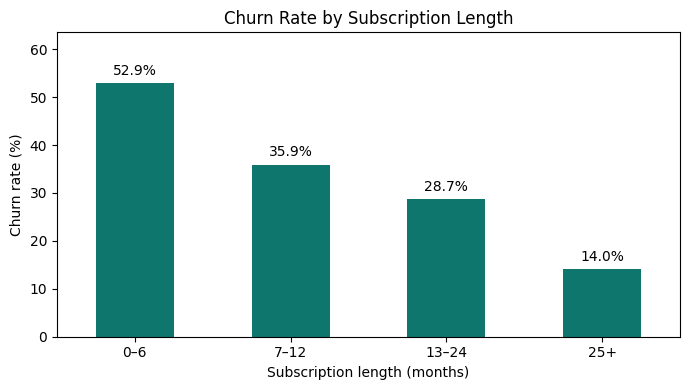

بلغت نسبة ترك الخدمة 52.9% لفئة 0 إلى 6 أشهر، مقابل 14.0% لفئة 25 شهرًا فأكثر.


In [11]:
rates = tenure_summary["ChurnRate"]

ax = rates.plot.bar(figsize=(7, 4), color="#0f766e", rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)
ax.set(
    title="Churn Rate by Subscription Length",
    xlabel="Subscription length (months)",
    ylabel="Churn rate (%)"
)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

print("بلغت نسبة ترك الخدمة 52.9% لفئة 0 إلى 6 أشهر، مقابل 14.0% لفئة 25 شهرًا فأكثر.")